# auto-econ-sentiment: six dictionaries on FOMC statements
This notebook demonstrates the basics of the `AutoEconSentiment` pipeline: loading data, cleaning it, and running lexical sentiment analysis.

Adapted from [https://github.com/corybaird/auto-econ-sentiment/blob/main/notebooks/autoecon_demo.ipynb](https://github.com/corybaird/auto-econ-sentiment/blob/main/notebooks/autoecon_demo.ipynb).

In [1]:
import yaml
from auto_econ_sentiment.pipeline import AutoEconSentiment
from economic_libraries.notebooks import fetch

## 1. Setup Data
We will use the FOMC statement sample from the auto-econ-sentiment repository, committed in `data/raw/notebooks/` and hash-checked.

In [2]:
import_file_path = str(fetch("fomc_statements"))
export_path = "data/final/sentiment_notebook/"

analyzer = AutoEconSentiment(
    import_file_path=import_file_path,
    text_column="text",
    date_column="date",
    export_path=export_path
)

In [3]:
df_raw = analyzer.load_data()
df_raw.head(2)

,Unnamed: 0,date,text,type,event,link,title,speaker,text_len,release_date
245,0,1994-02-04,Chairman Alan Greenspan announced today that t...,Policy Statement,Policy Statement,https://www.federalreserve.gov/fomc/19940322de...,None,None,NaN,1994-02-04
246,1,1994-03-22,Chairman Alan Greenspan announced today that t...,Policy Statement,Policy Statement,https://www.federalreserve.gov/fomc/19940204de...,None,None,NaN,1994-03-22


## 2. Run Pipeline
We run the cleaning and sentiment scoring in one go using the `run()` method.

## 2.A Run pipeline

In [4]:
df_raw, df_clean, df_sentiment = analyzer.run(
    clean_config={"tokenize": True, "stem": True},
    dictionaries={
        "unstemmed": ["correa", "hubert", "lm", "hiv"],
        "stemmed": ["ap", "bn"]
        },
    aggregation_methods=["posneg", "allwords"],
    export_results=True
)

df_sentiment.head()

Tokenizing text:   0%|                                 | 0/232 [00:00<?, ?it/s]

Tokenizing text:  13%|███                    | 31/232 [00:00<00:00, 306.98it/s]

Tokenizing text:  27%|██████▏                | 62/232 [00:00<00:00, 195.07it/s]

Tokenizing text:  38%|████████▋              | 88/232 [00:00<00:00, 216.83it/s]

Tokenizing text:  55%|████████████          | 127/232 [00:00<00:00, 272.90it/s]

Tokenizing text:  68%|██████████████▉       | 157/232 [00:00<00:00, 279.52it/s]

... (15 outputs left out)

Lexical Methods:  83%|██████████████████████▌    | 5/6 [00:01<00:00,  2.94it/s]

Lexical Methods: 100%|███████████████████████████| 6/6 [00:01<00:00,  3.06it/s]

Lexical Methods: 100%|███████████████████████████| 6/6 [00:01<00:00,  3.02it/s]

,correa_counttoken_positive_posneg,correa_counttoken_negative_posneg,correa_words_positive_posneg,correa_words_negative_posneg,correa_sentiment_posneg,correa_sentiment_posneg_net,correa_counttoken_positive_allwords,correa_counttoken_negative_allwords,correa_words_positive_allwords,correa_words_negative_allwords,...,bn_words_negative_posneg_stem,bn_sentiment_posneg_stem,bn_sentiment_posneg_stem_net,bn_counttoken_positive_allwords_stem,bn_counttoken_negative_allwords_stem,bn_words_positive_allwords_stem,bn_words_negative_allwords_stem,bn_counttoken_total_allwords_stem,bn_sentiment_allwords_stem,bn_sentiment_allwords_stem_net
id_text,,,,,,,,,,,,,,,,,,,,,
1,0,0,{},{},1.0,0.0,0,0,{},{},...,{'small': 1},1.333333,0.333333,2,1,{'increas': 2},{'small': 1},25,1.040000,0.040000
2,1,0,{'enhance': 1},{},2.0,1.0,1,0,{'enhance': 1},{},...,{'small': 1},1.500000,0.500000,3,1,"{'firm': 1, 'increas': 2}",{'small': 1},58,1.034483,0.034483
3,0,0,{},{},1.0,0.0,0,0,{},{},...,{'small': 1},1.333333,0.333333,2,1,{'increas': 2},{'small': 1},22,1.045455,0.045455
4,2,0,"{'effective': 1, 'favorable': 1}",{},2.0,1.0,2,0,"{'effective': 1, 'favorable': 1}",{},...,{},2.000000,1.000000,2,0,{'increas': 2},{},96,1.020833,0.020833
5,1,0,{'contained': 1},{},2.0,1.0,1,0,{'contained': 1},{},...,{},2.000000,1.000000,1,0,{'high': 1},{},80,1.012500,0.012500


### 2.A.A Clean data

In [5]:
df_clean.loc[:, 'release_date':].head(2)

,release_date,id_text,text_clean,text_tokens,text_tokens_str,text_stems
245,1994-02-04,1,Chairman Alan Greenspan announced today that t...,"[chairman, alan, greenspan, announced, today, ...",chairman alan greenspan announced today that t...,chairman alan greenspan announc today that the...
246,1994-03-22,2,Chairman Alan Greenspan announced today that t...,"[chairman, alan, greenspan, announced, today, ...",chairman alan greenspan announced today that t...,chairman alan greenspan announc today that the...


## 2.1 Sentiment

### 2.1.1 Using positive and negative words only in the demoninator

*   **`posneg`**: Normalizes sentiment by the total count of matched sentiment words. 
    $$ \text{Sentiment}_{\text{posneg}} = 1 + \frac{N_{\text{pos}} - N_{\text{neg}}}{N_{\text{pos}} + N_{\text{neg}}} $$

<Axes: xlabel='id_text'>

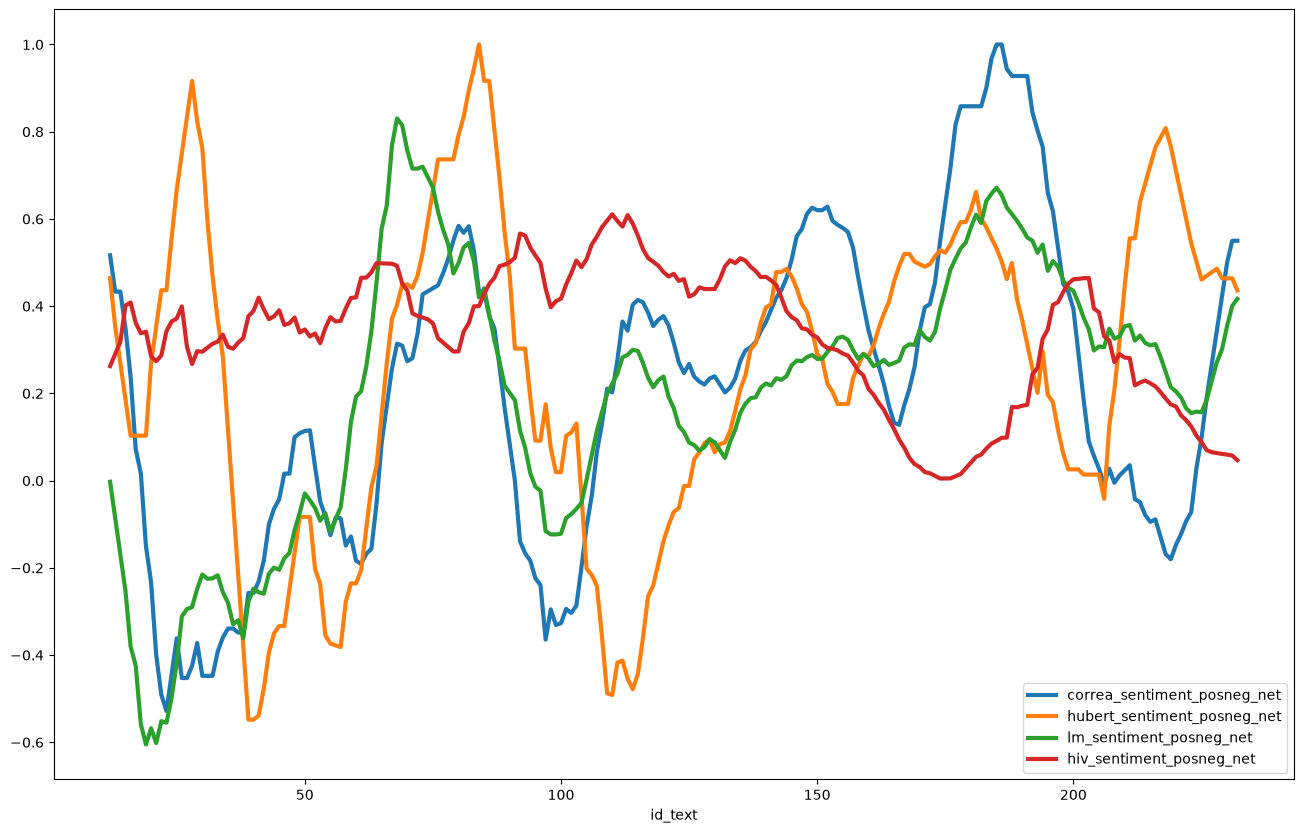

In [6]:
df_sentiment.filter(regex='sentiment_posneg_net').rolling(12).mean().plot(figsize = (16,10), linewidth=3)

### 2.1.2 Using ALL words only in the demoninator

<Axes: xlabel='id_text'>

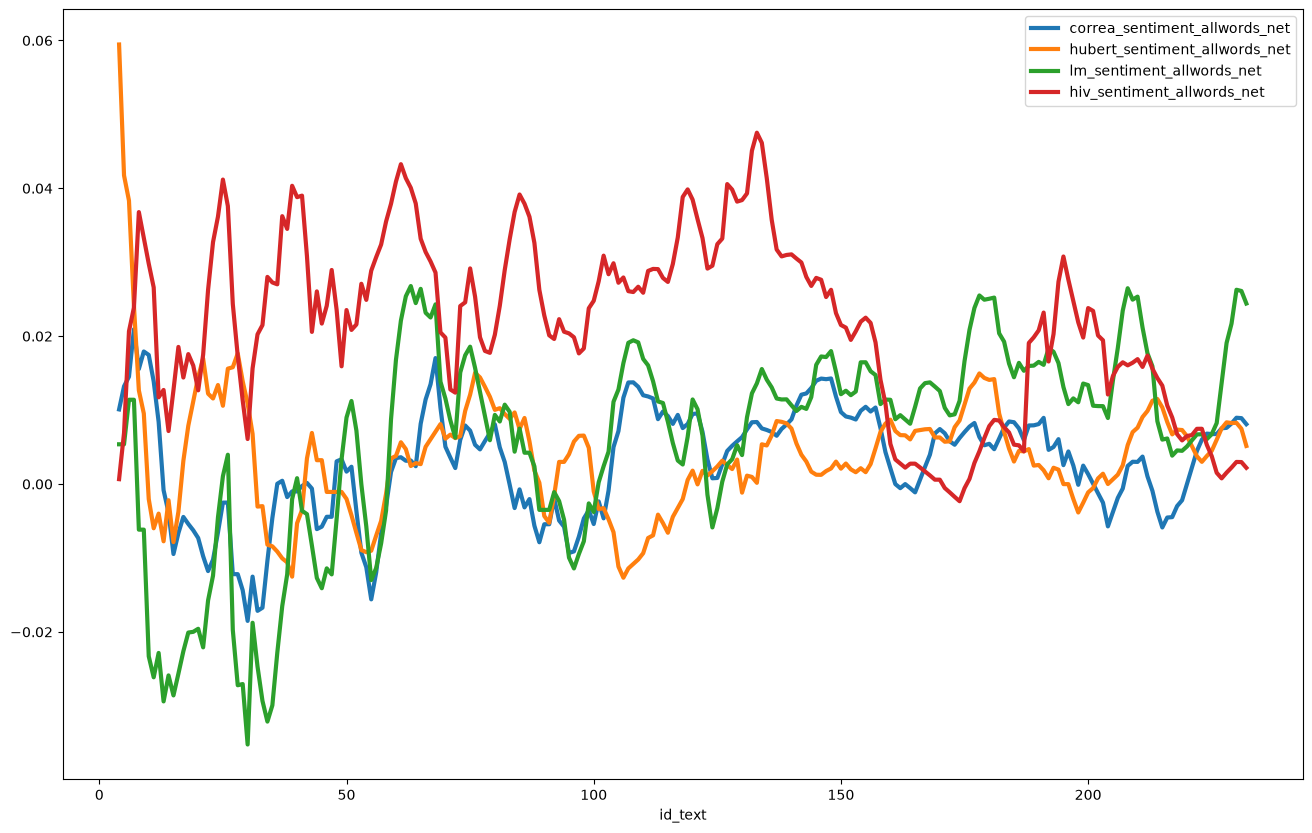

In [7]:
df_sentiment.filter(regex='sentiment_allwords_net').rolling(4).mean().plot(figsize = (16,10), linewidth=3)

## 2.2 Sanity Checking

The final output DataFrame contains the following core columns for each configured dictionary (e.g., `hubert`):

| Column Pattern               | Description                                                                         |
| ---------------------------- | ----------------------------------------------------------------------------------- |
| `{dict}_counttoken_positive` | Total count of positive words identified by the dictionary.                         |
| `{dict}_counttoken_negative` | Total count of negative words identified by the dictionary.                         |
| `{dict}_counttoken_total`    | Total tokens in the document (only present if using `allwords` method).             |
| `{dict}_words_positive`      | JSON-like mapping of the specific positive words found and their counts.            |
| `{dict}_words_negative`      | JSON-like mapping of the specific negative words found and their counts.            |
| `{dict}_sentiment_{method}`  | Final computed sentiment score using the specified method (`posneg` or `allwords`). |

### 2.2.A Match word count to original text

In [8]:
next(sentence for sentence in df_clean.text_clean.iloc[-1].split(".") if "impede" in sentence)

" The Committee would be prepared to adjust the stance of monetary policy as appropriate if risks emerge that could impede the attainment of the Committee's goals"

In [9]:
df_sentiment.filter(regex='correa_counttoken_negative').tail(1)

,correa_counttoken_negative_posneg,correa_counttoken_negative_allwords
id_text,,
232,1,1


In [10]:
df_sentiment.filter(regex='correa_words_negative').tail(1)

,correa_words_negative_posneg,correa_words_negative_allwords
id_text,,
232,{'impede': 1},{'impede': 1}


## 2.2.1 Negative counts from both methods should be equal because aggregation only takes place in denominator

<Axes: xlabel='id_text'>

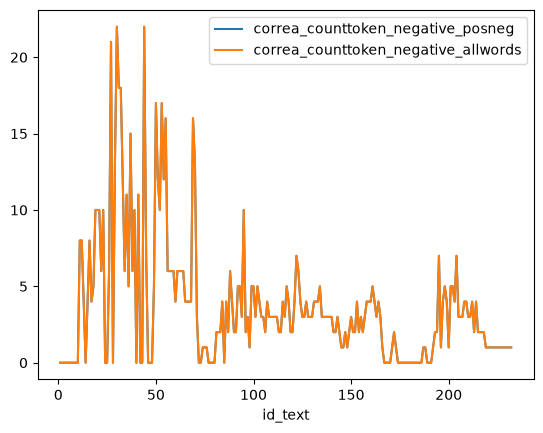

In [11]:
df_sentiment.filter(regex='correa_counttoken_negative').plot()

### 2.2 Negative word counts differ greatly by method

<Axes: xlabel='id_text'>

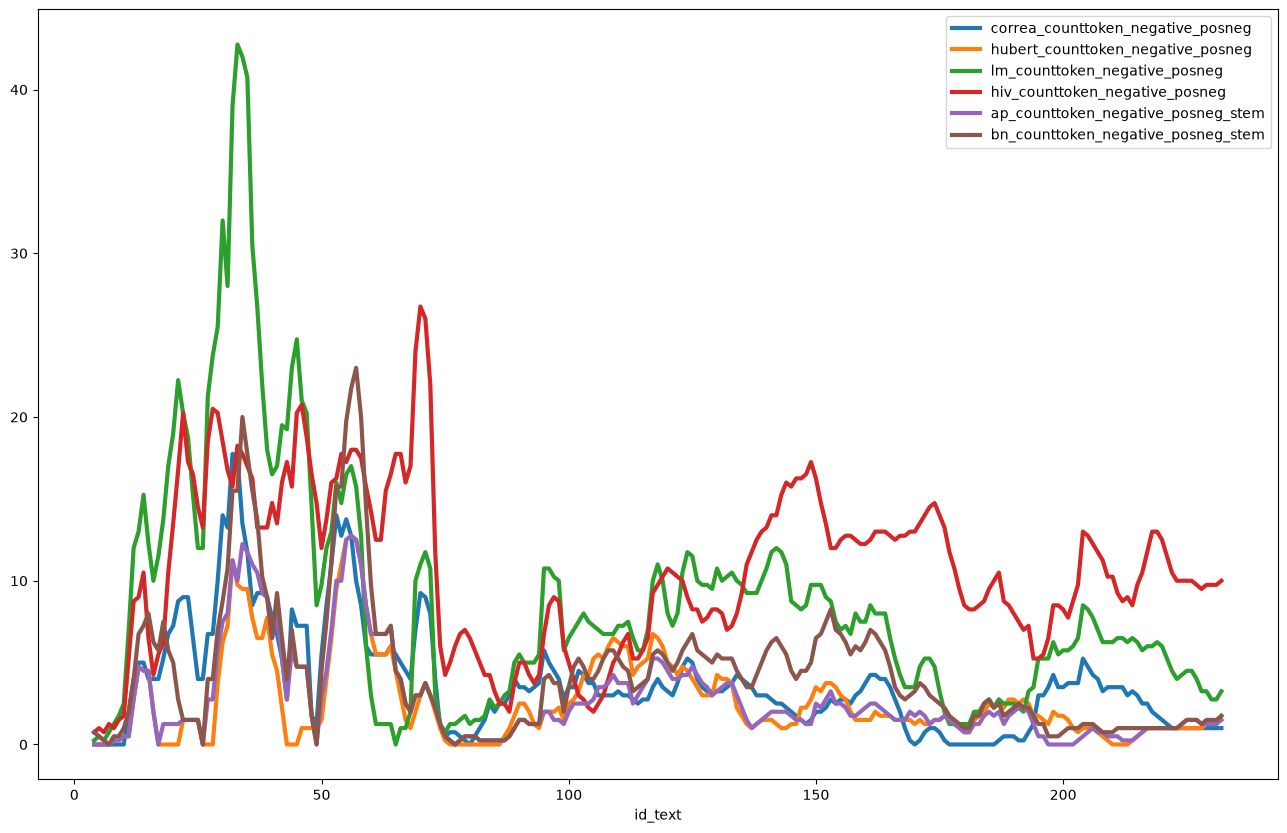

In [12]:
df_sentiment.filter(regex='counttoken_negative_posneg').rolling(4).mean().plot(figsize = (16,10), linewidth=3)

## 3. Dictionary Examples
View the words contained in a specific dictionary.

In [13]:
def show_dictionary_example(dictionary_name, limit=10):
    from importlib.resources import files

    master_dict = yaml.safe_load((files("auto_econ_sentiment") / "data/lexical_master_dict.yaml").read_text())
    
    if dictionary_name in master_dict:
        print(f"--- Dictionary: {dictionary_name} ---")
        pos = master_dict[dictionary_name].get('positive', [])
        neg = master_dict[dictionary_name].get('negative', [])
        print(f"Positive examples: {pos[:limit]} ... ({len(pos)} total)")
        print(f"Negative examples: {neg[:limit]} ... ({len(neg)} total)")
    else:
        print(f"Dictionary {dictionary_name} not found.")

show_dictionary_example("lm")

--- Dictionary: lm ---
Positive examples: ['able', 'abundance', 'abundant', 'acclaimed', 'accomplish', 'accomplished', 'accomplishes', 'accomplishing', 'accomplishment', 'accomplishments'] ... (354 total)
Negative examples: ['abandon', 'abandoned', 'abandoning', 'abandonment', 'abandonments', 'abandons', 'abdicated', 'abdicates', 'abdicating', 'abdication'] ... (2355 total)
